# Network Intrusion Detection

In [5]:
import sys
sys.path.append("..")  # so we can import the src package from the notebooks/ folder

from src.cic_data_loader import *
from src.preprocessing import *
from src.model import *
from src.evaluate import *
from src.neural_net import *
from src.compare import *
from src.tree_models import *

## 1. Download and load the data

In [6]:
df = cic_load_data(data_dir="../data")

print(df.shape)
#Should be no nulls or duplicates in the dataset
display(df.isnull().sum().sum())
display(df.duplicated().sum()) 

(2563107, 80)


np.int64(0)

np.int64(0)

## 2. Split the data

In [7]:
#Test set is firday by default, but can be changed to any day of the week.
train, test = split_by_day(df)

print("Training rows:", len(train))
print("Test rows:", len(test))
train.head()

Training rows: 1947674
Test rows: 615433


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day,is_attack
703245,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703246,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703249,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703250,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0
703253,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,monday,0


## 3. Prepare features

This encodes the text columns (`protocol_type`, `service`, `flag`) into numbers and scales everything, since logistic regression needs numeric, comparably-sized inputs.

In [8]:
X_train, X_test, y_train, y_test, scaler = prepare_cic_features(train, test, drop_cols=("Label", "Day", "is_attack"))

print("Feature matrix shape:", X_train.shape)

Feature matrix shape: (1947674, 77)


## 4. Train the model

In [9]:
model = train_model(X_train, y_train)
print("Model trained")

Model trained


## 5. Evaluate

We look at accuracy, precision, and recall rather than just accuracy, since missing an attack is usually worse than a false alarm.

In [10]:
y_pred = predict(model, X_test)
print_report(y_test, y_pred)

Accuracy:  0.7739
Precision: 0.9968
Recall:    0.3705

Confusion matrix (rows=actual, cols=predicted):
[[394514    263]
 [138911  81745]]

              precision    recall  f1-score   support

      normal       0.74      1.00      0.85    394777
      attack       1.00      0.37      0.54    220656

    accuracy                           0.77    615433
   macro avg       0.87      0.68      0.70    615433
weighted avg       0.83      0.77      0.74    615433



## 6. Create other models to compare

All the ones using mlp are pretty heavy.

In [11]:
lr_model = model

models = {
    "Logistic Regression": lr_model,
}


## MLP Model Options

In [12]:
%%script false --no-raise-error
# This entire cell will be skipped during "Run All"

#16 nodes with 42 random states
mlp_model = train_mlp(X_train, y_train, hidden_layer_size=(16,))
models.update({"Neural Net (16 nodes)": mlp_model})

In [13]:
%%script false --no-raise-error

#32 nodes with 42 random states
mlp_model = train_mlp(X_train, y_train, hidden_layer_size=(32,))
models.update({"Neural Net (32 nodes)": mlp_model})

In [14]:
%%script false --no-raise-error

#64 nodes with 64 random states
mlp_model_2 = train_mlp(X_train, y_train, hidden_layer_size=(64,), random_state=64)
models.update({"Neural Net (64 nodes)": mlp_model_2})

## CURRENT BEST MLP MODEL

In [15]:
#two sets of 32 and 16 nodes with 42 random states
mlp_model_3 = train_mlp(X_train, y_train, hidden_layer_size=(32, 16))
models.update({"Neural Net (32-16 nodes)": mlp_model_3})

In [16]:
%%script false --no-raise-error

#two sets of 32 and 32 nodes with 42 random states
mlp_model_3 = train_mlp(X_train, y_train, hidden_layer_size=(32, 32))
models.update({"Neural Net (32-32 nodes)": mlp_model_3})

## HGB (Tree) Model Options

In [17]:
%%script false --no-raise-error
hgb_model = train_hgb(X_train, y_train)
models.update({"Default Tree Model (HGB)": hgb_model})

In [18]:
%%script false --no-raise-error
# Increased Depth to 3
hgb_model_1 = train_hgb(X_train, y_train, max_depth=3)
models.update({"Tree Model (Tree Depth 3)": hgb_model_1})

In [19]:
%%script false --no-raise-error
# Increased Depth to 3 and Number of Iterations to 200
hgb_model_1 = train_hgb(X_train, y_train, max_depth=3, max_iter=200)
models.update({"Tree Model (Tree Depth 3 and 200 Iterations)": hgb_model_1})

In [20]:
%%script false --no-raise-error
# Increased Depth to 5 and Number of Iterations to 200
hgb_model_1 = train_hgb(X_train, y_train, max_depth=5, max_iter=200)
models.update({"Tree Model (Tree Depth 5 and 200 Iterations)": hgb_model_1})

## 7. Compare the new models

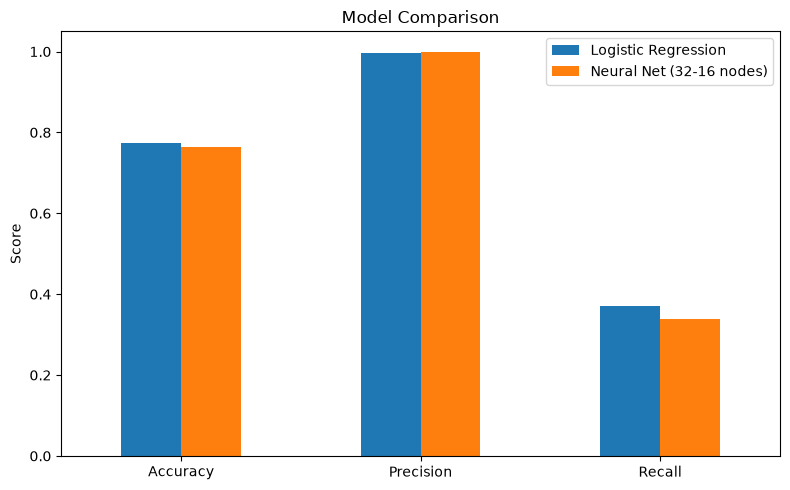

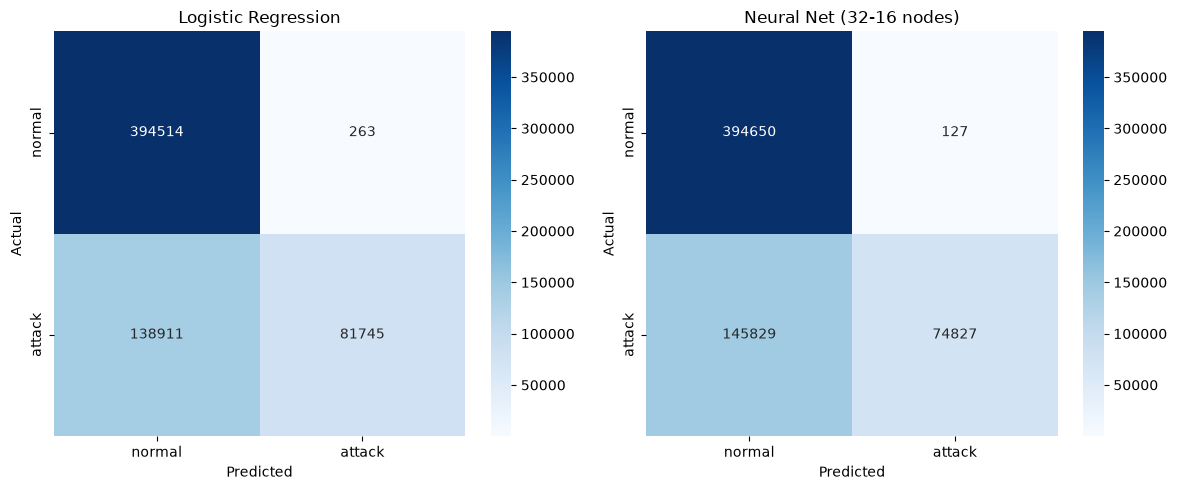

In [21]:
results_df, confusion_matrices = compare_models(models, X_test, y_test)
# print(results_df)
plot_bar_chart(results_df, title="Model Comparison")
plot_confusion_matrices(confusion_matrices)

## 8. K-Fold Testing

Logistic Regression is done!


/home/storm/Desktop/School Work/CSC Projects/NetworkIntrusionDetector/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


Neural Net (32-16 nodes) is done!


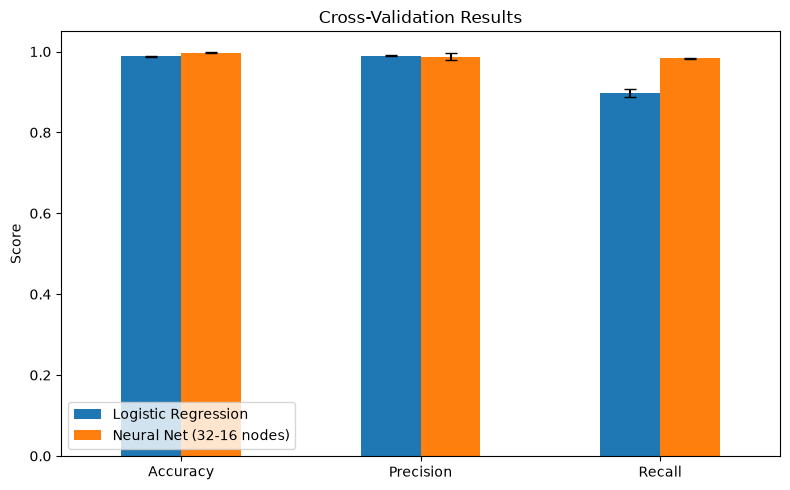

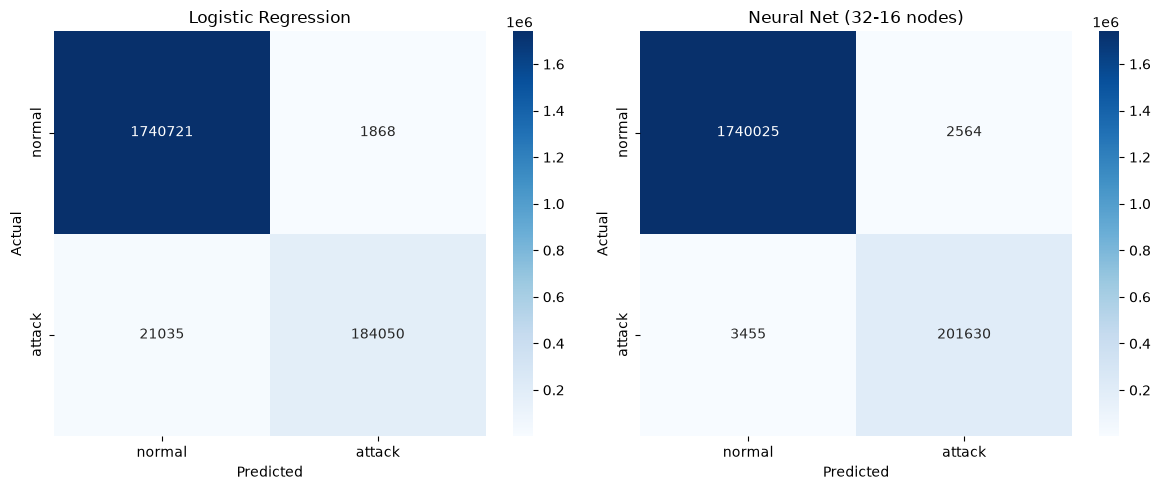

In [22]:
from sklearn.model_selection import StratifiedKFold, GroupKFold
from src.cross_validation import *

# Plain k-fold: shuffle the rows into 5 parts, train on 4, test on 1, repeat
mean, stds, confusion_matrices = run_cv(models, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42))
plot_bar_chart(mean, title="Cross-Validation Results", errors=stds)
plot_confusion_matrices(confusion_matrices)

Logistic Regression is done!
Neural Net (32-16 nodes) is done!
Default Tree Model (HGB) is done!
Tree Model (Tree Depth 3) is done!
Tree Model (Tree Depth 3 and 200 Iterations) is done!


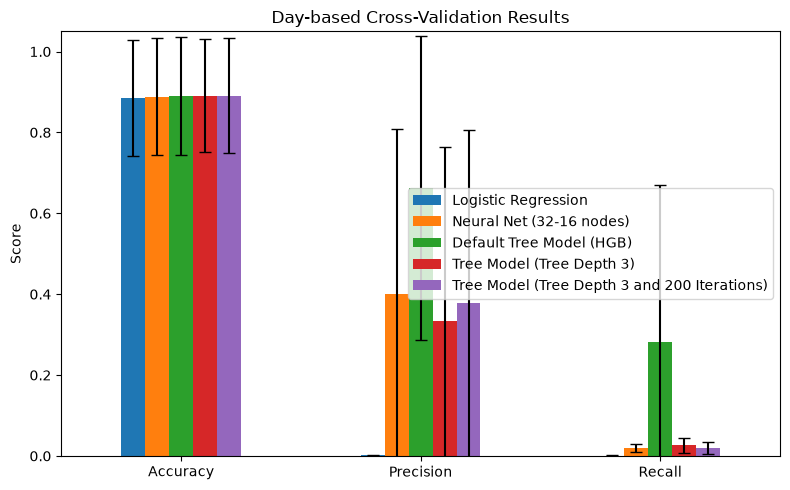

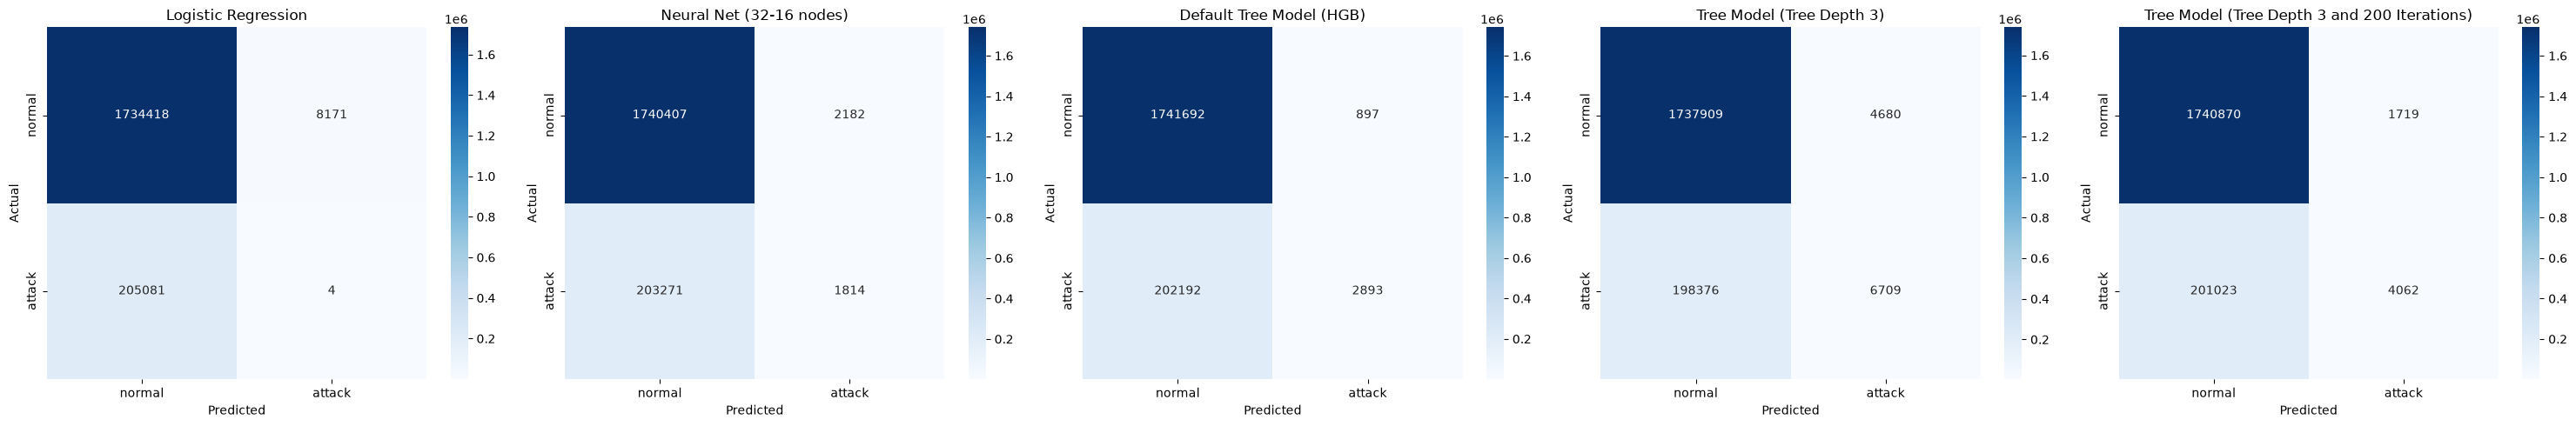

In [ ]:
from sklearn.model_selection import StratifiedKFold, GroupKFold
from src.cross_validation import *

# Day-based: each fold holds out whole days
groups = train["Day"].replace({"monday": "tuesday"})
mean, stds, confusion_matrices = run_cv(models, X_train, y_train, cv=GroupKFold(n_splits=groups.nunique()), groups=groups)
plot_bar_chart(mean, title="Day-based Cross-Validation Results", errors=stds, path="day_cv_comparison.png")
plot_confusion_matrices(confusion_matrices, path="day_confusion_matrices.png")